Original shape: (7043, 42)
Cleaned shape: (7043, 20)

Missing values:
 Series([], dtype: int64)

Duplicate rows: 22


C:\Users\subha\AppData\Local\Temp\ipykernel_15352\267902887.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Churn Label', data=df, palette='Set2')


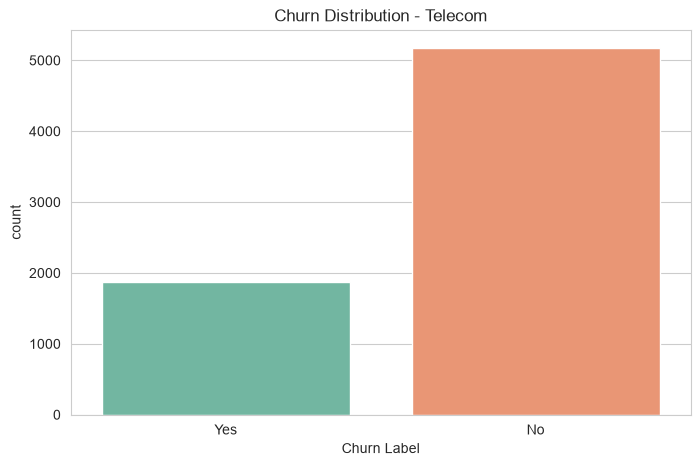

Churn Label
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


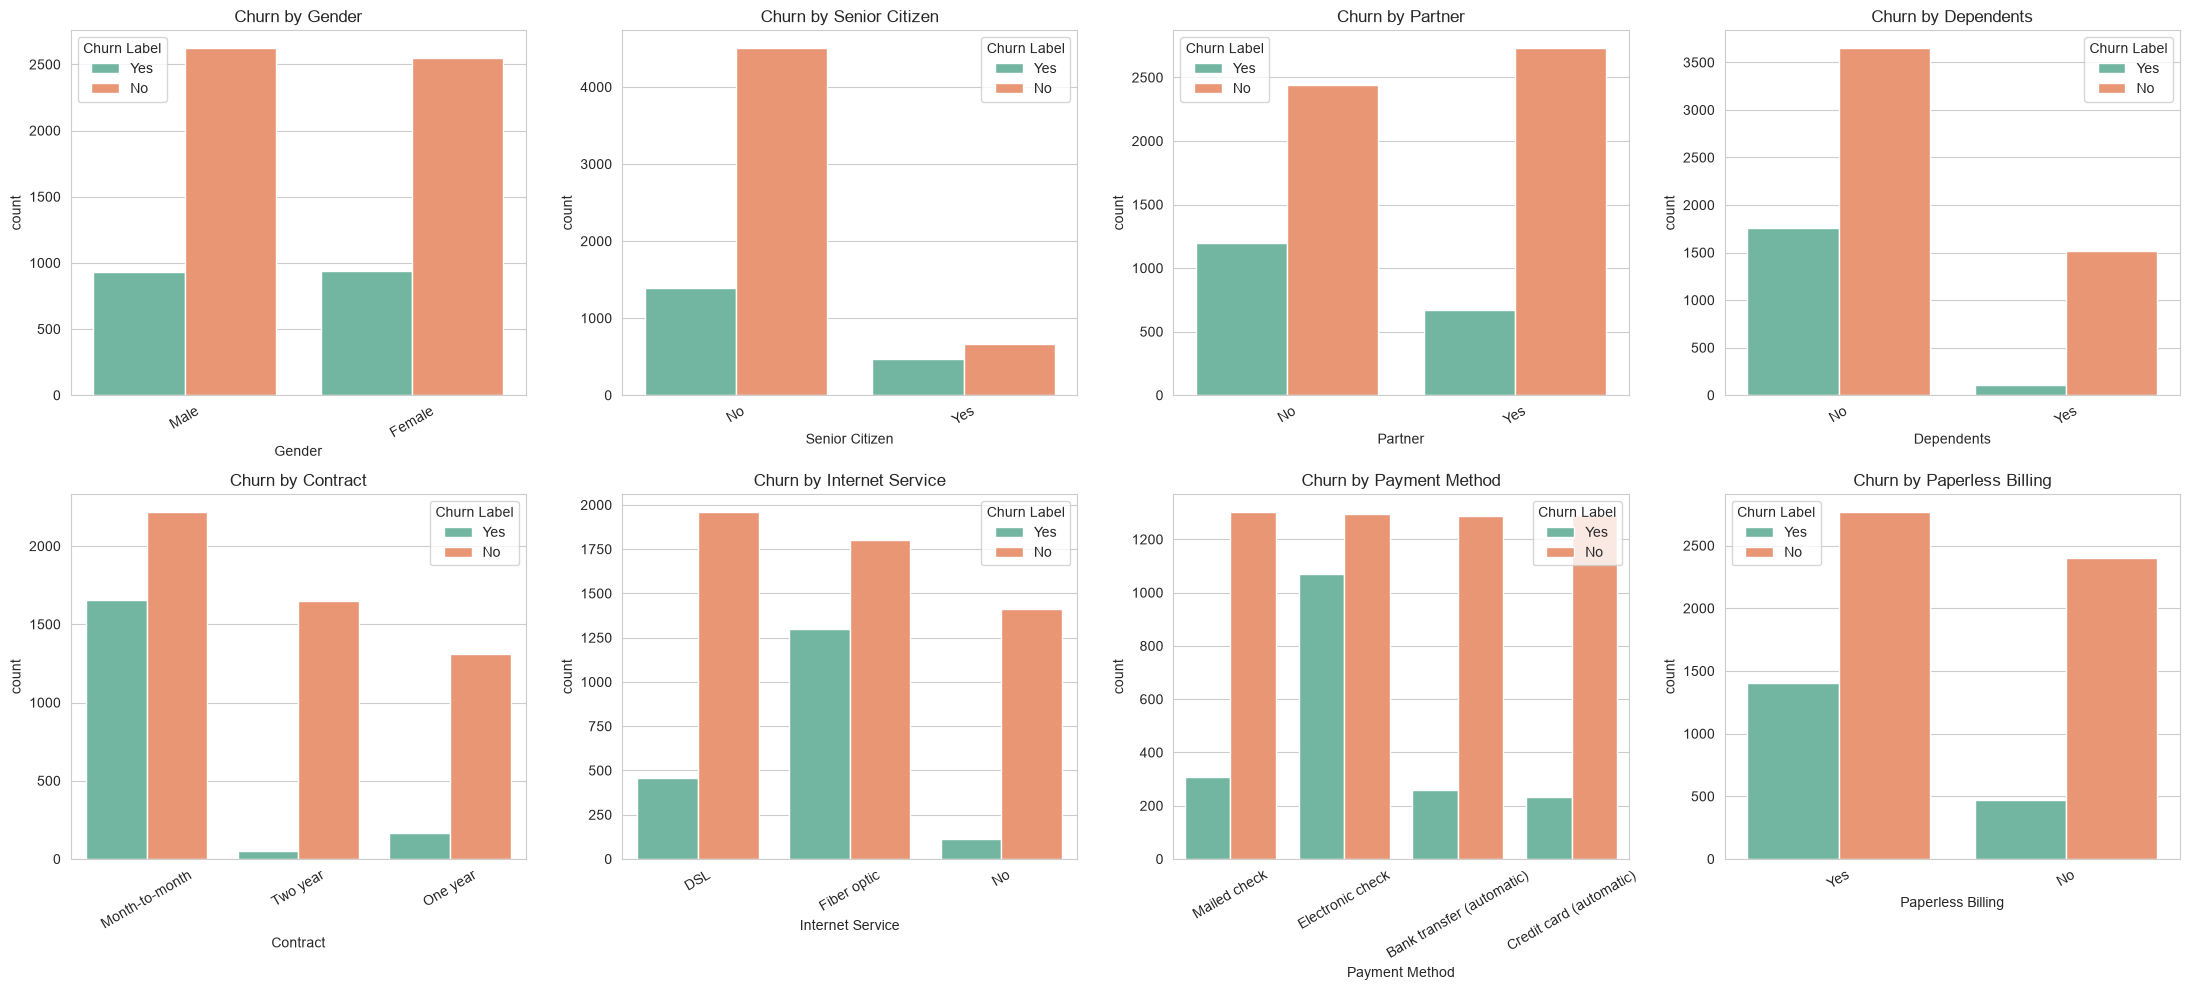

C:\Users\subha\AppData\Local\Temp\ipykernel_15352\267902887.py:73: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Churn Label', y=col, data=df, ax=ax, palette='Set2')
C:\Users\subha\AppData\Local\Temp\ipykernel_15352\267902887.py:73: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Churn Label', y=col, data=df, ax=ax, palette='Set2')
C:\Users\subha\AppData\Local\Temp\ipykernel_15352\267902887.py:73: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Churn Label', y=col, data=df, ax=ax, palette='Set2')


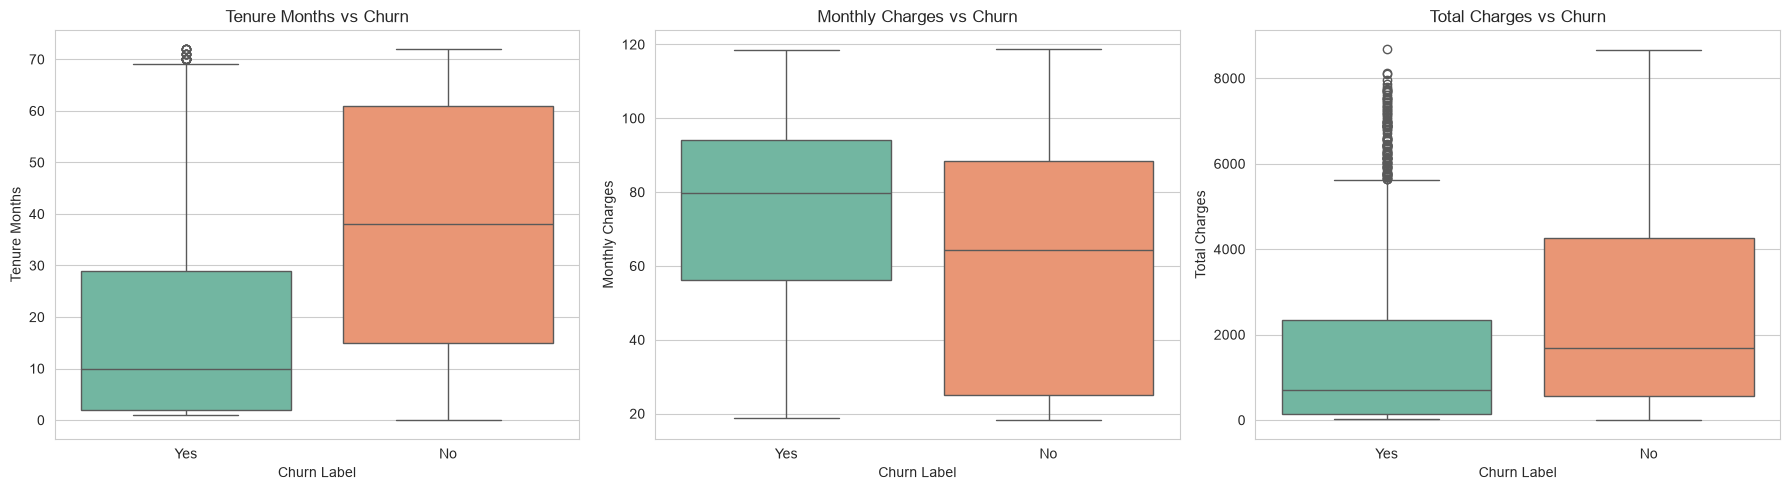

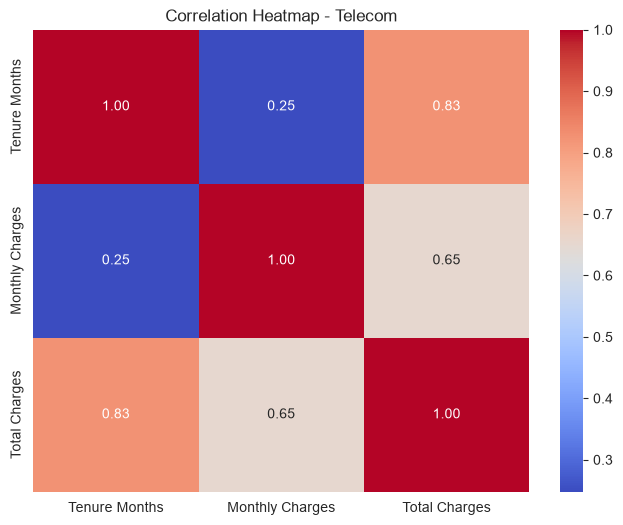

Gender : ['Female', 'Male']
Senior Citizen : ['No', 'Yes']
Partner : ['No', 'Yes']
Dependents : ['No', 'Yes']
Phone Service : ['No', 'Yes']
Multiple Lines : ['No', 'No phone service', 'Yes']
Internet Service : ['DSL', 'Fiber optic', 'No']
Online Security : ['No', 'No internet service', 'Yes']
Online Backup : ['No', 'No internet service', 'Yes']
Device Protection : ['No', 'No internet service', 'Yes']
Tech Support : ['No', 'No internet service', 'Yes']
Streaming TV : ['No', 'No internet service', 'Yes']
Streaming Movies : ['No', 'No internet service', 'Yes']
Contract : ['Month-to-month', 'One year', 'Two year']
Paperless Billing : ['No', 'Yes']
Payment Method : ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
Train shape: (5634, 19) | Test shape: (1409, 19)


C:\Users\subha\AppData\Local\Temp\ipykernel_15352\267902887.py:98: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_feature_cols = X.select_dtypes(include=['object']).columns.tolist()


Decision Tree best params: {'max_depth': 4, 'min_samples_leaf': 1, 'min_samples_split': 2}
Random Forest best params: {'max_depth': 6, 'min_samples_split': 2, 'n_estimators': 200}


C:\Users\subha\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM best params: {'C': 0.1, 'gamma': 'auto', 'kernel': 'rbf'}

--- Overfitting Check ---
Decision Tree: Train=0.771, Test=0.756, Gap=0.015 ✅ OK
Random Forest: Train=0.783, Test=0.752, Gap=0.031 ✅ OK
SVM: Train=0.765, Test=0.747, Gap=0.018 ✅ OK

--- Test Set Evaluation ---

Decision Tree:
  Accuracy: 0.756 | Precision: 0.529 | Recall: 0.725 | F1: 0.612 | ROC-AUC: 0.820

Random Forest:
  Accuracy: 0.752 | Precision: 0.522 | Recall: 0.807 | F1: 0.634 | ROC-AUC: 0.852

SVM:
  Accuracy: 0.747 | Precision: 0.516 | Recall: 0.775 | F1: 0.620 | ROC-AUC: 0.840

            Model  Accuracy  Precision    Recall        F1   ROC-AUC
0  Decision Tree  0.755855   0.529297  0.724599  0.611738  0.820019
1  Random Forest  0.752307   0.521589  0.807487  0.633788  0.851754
2            SVM  0.747339   0.516014  0.775401  0.619658  0.840333


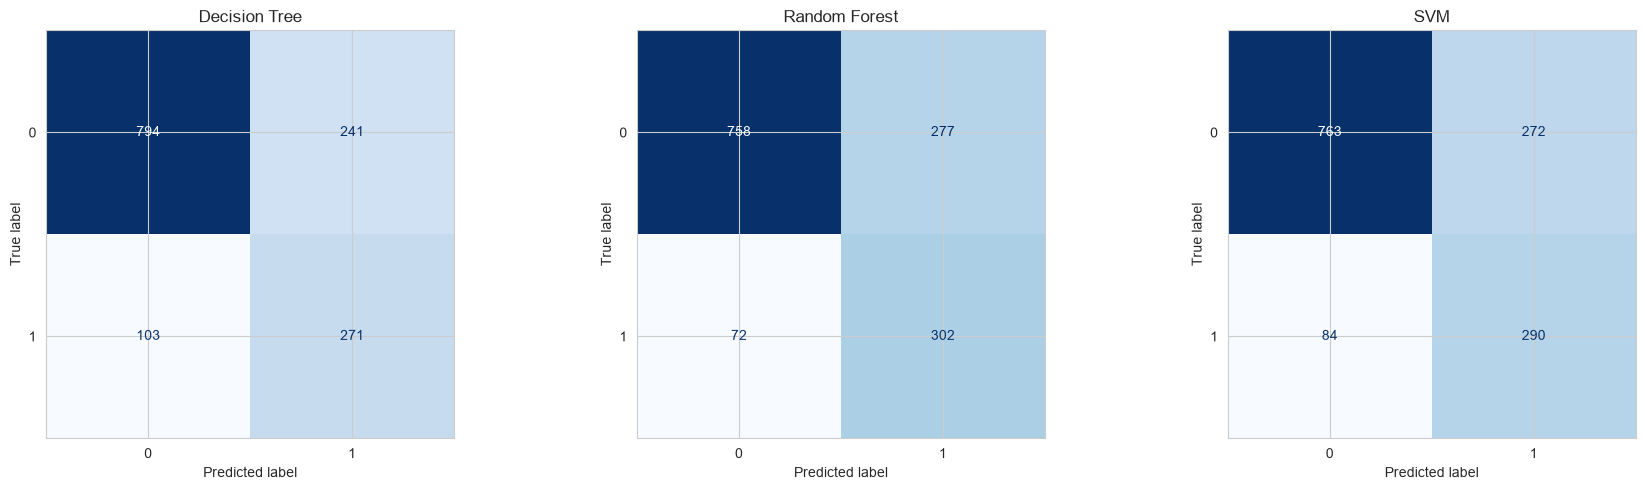

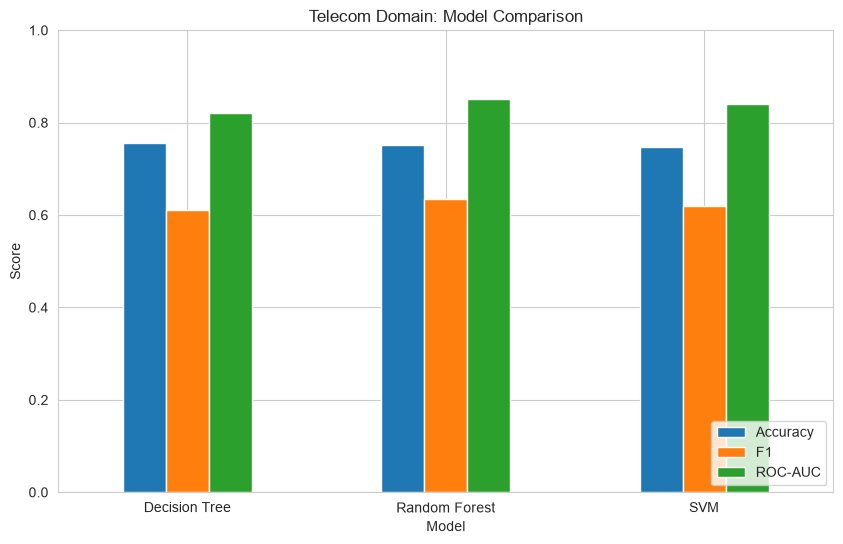


🏆 Best model: Random Forest
Saved: telecom_model.pkl, telecom_scaler.pkl, telecom_encoders.pkl


In [1]:
# ============================================================
# TELECOM CHURN - FULL PIPELINE
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                               f1_score, roc_auc_score, confusion_matrix,
                               ConfusionMatrixDisplay)

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)

# ============================================================
# STEP 1: Load and clean
# ============================================================
df = pd.read_excel('../data/raw/Telco_customer_churn.xlsx')
print("Original shape:", df.shape)

# Drop junk/leaking/location columns
drop_cols = ['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code',
             'Lat Long', 'Latitude', 'Longitude', 'Churn Value', 'Churn Score',
             'CLTV', 'Churn Reason']
df = df.drop(columns=[c for c in df.columns if 'Unnamed' in c] + drop_cols, errors='ignore')

print("Cleaned shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum()[df.isnull().sum() > 0])
print("\nDuplicate rows:", df.duplicated().sum())

# Fix Total Charges (blank strings for new customers with 0 tenure)
df['Total Charges'] = pd.to_numeric(df['Total Charges'], errors='coerce')
df['Total Charges'] = df['Total Charges'].fillna(0)

# ============================================================
# STEP 2: EDA - Target distribution
# ============================================================
plt.figure()
sns.countplot(x='Churn Label', data=df, palette='Set2')
plt.title('Churn Distribution - Telecom')
plt.show()
print(df['Churn Label'].value_counts(normalize=True) * 100)

# ============================================================
# STEP 3: EDA - Categorical features vs churn
# ============================================================
cat_cols = ['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Contract',
            'Internet Service', 'Payment Method', 'Paperless Billing']

fig, axes = plt.subplots(2, 4, figsize=(22, 10))
for ax, col in zip(axes.flatten(), cat_cols):
    sns.countplot(x=col, hue='Churn Label', data=df, ax=ax, palette='Set2')
    ax.set_title(f'Churn by {col}')
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

# ============================================================
# STEP 4: EDA - Numerical features vs churn
# ============================================================
num_cols = ['Tenure Months', 'Monthly Charges', 'Total Charges']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, num_cols):
    sns.boxplot(x='Churn Label', y=col, data=df, ax=ax, palette='Set2')
    ax.set_title(f'{col} vs Churn')
plt.tight_layout()
plt.show()

# ============================================================
# STEP 5: Correlation heatmap
# ============================================================
plt.figure(figsize=(8, 6))
corr = df.select_dtypes(include=[np.number]).corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap - Telecom')
plt.show()
for col in ['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service',
            'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup',
            'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies',
            'Contract', 'Paperless Billing', 'Payment Method']:
    print(col, ":", sorted(df[col].unique().tolist()))

# ============================================================
# STEP 6: Preprocessing
# ============================================================
X = df.drop(columns=['Churn Label'])
y = df['Churn Label'].map({'Yes': 1, 'No': 0})

cat_feature_cols = X.select_dtypes(include=['object']).columns.tolist()
encoders = {}
for col in cat_feature_cols:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col].astype(str))
    encoders[col] = le

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)

# ============================================================
# STEP 7: Train models with GridSearchCV
# ============================================================
results = {}

dt_params = {'max_depth': [4, 6, 8, 10], 'min_samples_split': [2, 5, 10], 'min_samples_leaf': [1, 2, 4]}
dt_grid = GridSearchCV(DecisionTreeClassifier(class_weight='balanced', random_state=42),
                        dt_params, cv=5, scoring='f1', n_jobs=-1)
dt_grid.fit(X_train_scaled, y_train)
results['Decision Tree'] = dt_grid.best_estimator_
print("Decision Tree best params:", dt_grid.best_params_)

rf_params = {'n_estimators': [100, 200], 'max_depth': [6, 10, 15], 'min_samples_split': [2, 5]}
rf_grid = GridSearchCV(RandomForestClassifier(class_weight='balanced', random_state=42),
                        rf_params, cv=5, scoring='f1', n_jobs=-1)
rf_grid.fit(X_train_scaled, y_train)
results['Random Forest'] = rf_grid.best_estimator_
print("Random Forest best params:", rf_grid.best_params_)

svm_params = {'C': [0.1, 1, 10], 'kernel': ['rbf', 'linear'], 'gamma': ['scale', 'auto']}
svm_grid = GridSearchCV(SVC(class_weight='balanced', probability=True, random_state=42),
                         svm_params, cv=5, scoring='f1', n_jobs=-1)
svm_grid.fit(X_train_scaled, y_train)
results['SVM'] = svm_grid.best_estimator_
print("SVM best params:", svm_grid.best_params_)

# ============================================================
# STEP 8: Overfitting check
# ============================================================
print("\n--- Overfitting Check ---")
for name, model in results.items():
    train_acc = accuracy_score(y_train, model.predict(X_train_scaled))
    test_acc = accuracy_score(y_test, model.predict(X_test_scaled))
    gap = train_acc - test_acc
    flag = "⚠️ possible overfitting" if gap > 0.10 else "✅ OK"
    print(f"{name}: Train={train_acc:.3f}, Test={test_acc:.3f}, Gap={gap:.3f} {flag}")

# ============================================================
# STEP 9: Evaluation metrics
# ============================================================
print("\n--- Test Set Evaluation ---")
metrics_summary = []
for name, model in results.items():
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)
    metrics_summary.append([name, acc, prec, rec, f1, auc])
    print(f"\n{name}:")
    print(f"  Accuracy: {acc:.3f} | Precision: {prec:.3f} | Recall: {rec:.3f} | F1: {f1:.3f} | ROC-AUC: {auc:.3f}")

metrics_df = pd.DataFrame(metrics_summary, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC'])
print("\n", metrics_df)

# ============================================================
# STEP 10: Confusion matrices
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, model) in zip(axes, results.items()):
    y_pred = model.predict(X_test_scaled)
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

# ============================================================
# STEP 11: Model comparison chart
# ============================================================
metrics_df.set_index('Model')[['Accuracy', 'F1', 'ROC-AUC']].plot(kind='bar', figsize=(10, 6))
plt.title('Telecom Domain: Model Comparison')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.show()

# ============================================================
# STEP 12: Save best model
# ============================================================
best_model_name = metrics_df.loc[metrics_df['F1'].idxmax(), 'Model']
best_model = results[best_model_name]
print(f"\n🏆 Best model: {best_model_name}")

os.makedirs('../models', exist_ok=True)
joblib.dump(best_model, '../models/telecom_model.pkl')
joblib.dump(scaler, '../models/telecom_scaler.pkl')
joblib.dump(encoders, '../models/telecom_encoders.pkl')
print("Saved: telecom_model.pkl, telecom_scaler.pkl, telecom_encoders.pkl")

In [2]:
print(X.columns.tolist())

['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges']


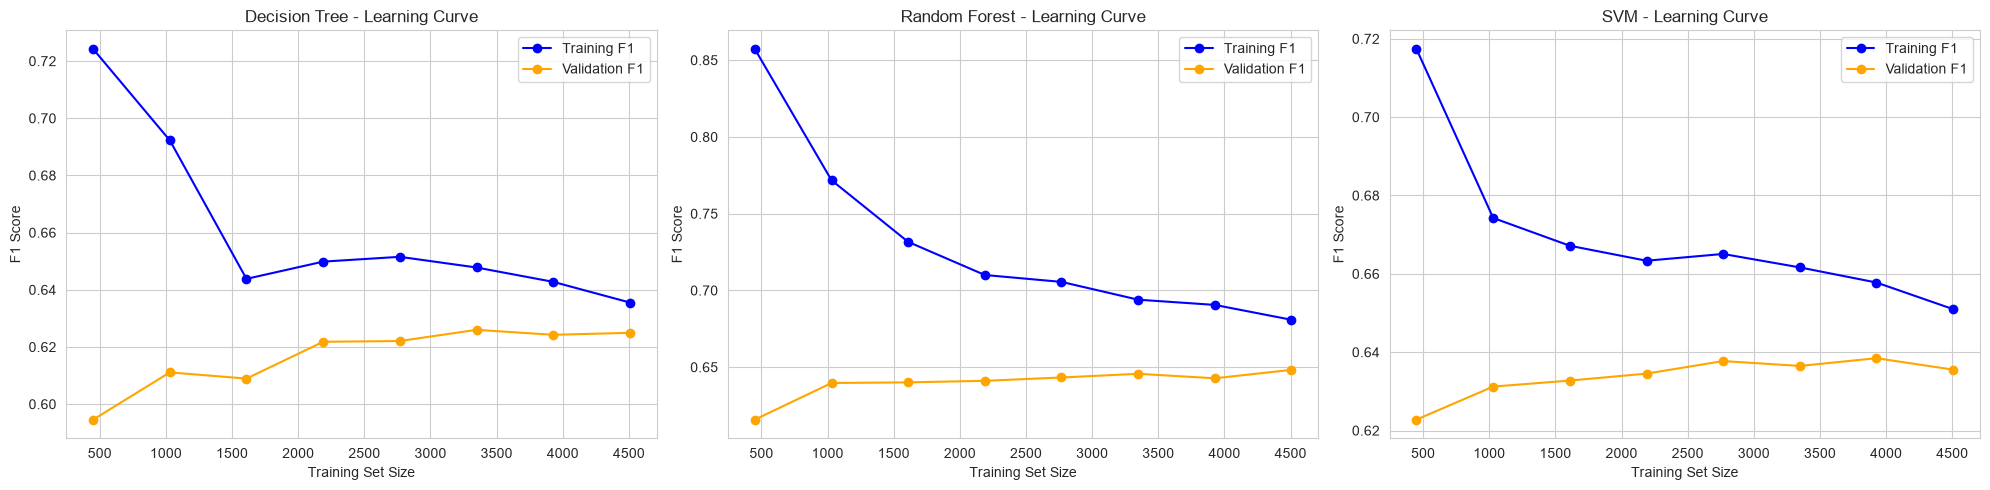


How to read this:
- If both lines are LOW and close together → UNDERFITTING (model too simple)
- If training line is HIGH but validation line is much LOWER (big gap) → OVERFITTING
- If both lines are HIGH and converge close together → GOOD FIT ✅



In [3]:
# ============================================================
# LEARNING CURVES - Overfitting/Underfitting diagnostic
# ============================================================
from sklearn.model_selection import learning_curve

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

for ax, (name, model) in zip(axes, results.items()):
    train_sizes, train_scores, val_scores = learning_curve(
        model, X_train_scaled, y_train, cv=5, scoring='f1',
        train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=-1
    )
    train_mean = train_scores.mean(axis=1)
    val_mean = val_scores.mean(axis=1)

    ax.plot(train_sizes, train_mean, 'o-', label='Training F1', color='blue')
    ax.plot(train_sizes, val_mean, 'o-', label='Validation F1', color='orange')
    ax.set_title(f'{name} - Learning Curve')
    ax.set_xlabel('Training Set Size')
    ax.set_ylabel('F1 Score')
    ax.legend(loc='best')
    ax.grid(True)

plt.tight_layout()
plt.show()

print("""
How to read this:
- If both lines are LOW and close together → UNDERFITTING (model too simple)
- If training line is HIGH but validation line is much LOWER (big gap) → OVERFITTING
- If both lines are HIGH and converge close together → GOOD FIT ✅
""")